# Botting Curation Simulation

Standalone replication of the botting experiments: four scoring modes are compared: baseline, content analysis only, behaviour analysis only, and both using the same random seed. Botting has low `true_quality` but high `apparent_quality`, so it can look attractive to voters while ranking poorly against the ground truth. Baseline rewards use `0.75 * (voting_power * voting_weight - 0.0049) / 50`; experimental rewards multiply that baseline reward by content quality and/or behavioral quality.

In [1]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau, spearmanr


def make_vote_rounds(total_rounds: int, post_count: int) -> set[int]:
    if total_rounds < 1 or post_count < 1:
        raise ValueError("total_rounds and post_count must be positive")
    if post_count == 1:
        return {1}
    if post_count >= total_rounds:
        return set(range(1, total_rounds + 1))
    return {
        1 + int(np.floor(index * (total_rounds - 1) / (post_count - 1)))
        for index in range(post_count)
    }


@dataclass(frozen=True)
class BottingConfig:
    rounds: int = 5_000
    players: int = 300
    bot_players: int = 50
    posts: int = 100
    bot_posts: int = 20
    attention_span: int = 10
    a: float = 0.02
    b: float = 0.0001
    sp: float = 1.0
    regen: float = 3 / (5 * 24 * 60 * 60)
    sigmoid_slope: float = 10.0
    sigmoid_midpoint: float = 0.5
    reward_pool_share: float = 0.75
    reward_offset: float = 0.0049
    reward_divisor: float = 50.0

    def __post_init__(self) -> None:
        if self.rounds < 1 or self.players < 1 or self.posts < 1:
            raise ValueError("rounds, players, and posts must be positive")
        if not 0 <= self.bot_players <= self.players:
            raise ValueError("bot_players must be between 0 and players")
        if not 0 <= self.bot_posts <= self.posts:
            raise ValueError("bot_posts must be between 0 and posts")
        if self.attention_span < 1:
            raise ValueError("attention_span must be positive")


@dataclass
class BottingResult:
    rounds: np.ndarray
    kendall_tau: np.ndarray
    spearman_rho: np.ndarray
    ndcg_at_10: np.ndarray
    botting_rank: np.ndarray
    human_rank: np.ndarray
    true_quality: np.ndarray
    apparent_quality: np.ndarray
    post_is_botting: np.ndarray
    author_bot_probability: np.ndarray
    final_scores: np.ndarray
    reward_scores: np.ndarray


def normalized_sigmoid(value: float, slope: float, midpoint: float) -> float:
    sigmoid = lambda x: 1.0 / (1.0 + np.exp(-slope * x))
    lower = sigmoid(-midpoint)
    upper = sigmoid(1.0 - midpoint)
    return float((sigmoid(value - midpoint) - lower) / (upper - lower))


def ndcg_at_10(order: np.ndarray, true_quality: np.ndarray) -> float:
    cutoff = min(10, len(order))
    gains = np.asarray(true_quality[order[:cutoff]], dtype=float)
    discounts = np.log2(np.arange(2, cutoff + 2))
    dcg = np.sum((2.0**gains - 1.0) / discounts)
    ideal_quality = np.sort(true_quality)[::-1][:cutoff]
    ideal_dcg = np.sum((2.0**ideal_quality - 1.0) / discounts)
    return float(dcg / ideal_dcg) if ideal_dcg else 0.0

In [2]:
class BottingCurationSimulation:

    def __init__(self, config: BottingConfig, seed: int, scoring_mode: str):
        self.config = config
        self.seed = seed
        valid_modes = {"baseline", "content", "behavior", "both"}
        if scoring_mode not in valid_modes:
            raise ValueError(f"scoring_mode must be one of {sorted(valid_modes)}")
        self.scoring_mode = scoring_mode
        self.rng = np.random.default_rng(seed)

        bot_start = config.posts - config.bot_posts
        self.post_is_botting = np.arange(config.posts) >= bot_start
        self.true_quality = np.where(
            self.post_is_botting,
            self.rng.uniform(0.0, 0.1, config.posts),
            self.rng.uniform(0.1, 1.0, config.posts),
        )
        self.apparent_quality = np.where(
            self.post_is_botting,
            self.rng.uniform(0.90, 0.98, config.posts),
            self.true_quality,
        )
        self.author_bot_probability = np.where(
            self.post_is_botting,
            self.rng.beta(9.0, 1.0, config.posts),
            self.rng.beta(1.0, 9.0, config.posts),
        )
        self.initial_order = self.rng.permutation(config.posts)
        self.vote_rounds = np.array(sorted(make_vote_rounds(config.rounds, config.posts)))

    def current_order(self, scores: np.ndarray) -> np.ndarray:
        return self.initial_order[np.argsort(-scores[self.initial_order], kind="stable")]

    def metrics(self, order: np.ndarray) -> tuple[float, float, float, float, float]:
        true_order = np.argsort(-self.true_quality, kind="stable")
        true_position = np.empty(self.config.posts, dtype=int)
        true_position[true_order] = np.arange(self.config.posts)
        actual_position = np.empty(self.config.posts, dtype=int)
        actual_position[order] = np.arange(self.config.posts)
        tau = kendalltau(true_position, actual_position).statistic
        rho = spearmanr(true_position, actual_position).statistic
        bot_positions = actual_position[self.post_is_botting] + 1
        human_positions = actual_position[~self.post_is_botting] + 1
        mean_botting_rank = float(np.mean(bot_positions)) if len(bot_positions) else float("nan")
        mean_human_rank = float(np.mean(human_positions)) if len(human_positions) else float("nan")
        return (
            float(np.nan_to_num(tau, nan=1.0)),
            float(np.nan_to_num(rho, nan=1.0)),
            ndcg_at_10(order, self.true_quality),
            mean_botting_rank,
            mean_human_rank,
        )

    def run(self) -> BottingResult:
        config = self.config
        scores = np.zeros(config.posts, dtype=float)
        reward_scores = np.zeros(config.posts, dtype=float)
        voting_power = np.ones(config.players, dtype=float)
        voted = np.zeros((config.players, config.posts), dtype=bool)
        metric_rows = []

        def record(round_number: int, order: np.ndarray) -> None:
            metric_rows.append((round_number, *self.metrics(order)))

        record(0, self.current_order(scores))
        for round_number in range(1, config.rounds + 1):
            voting_power = np.minimum(voting_power + config.regen, 1.0)
            if round_number in self.vote_rounds:
                order = self.current_order(scores)
                for player_id in range(config.players):
                    eligible = order[~voted[player_id, order]][:config.attention_span]
                    if len(eligible) == 0:
                        continue
                    if player_id >= config.players - config.bot_players:
                        bot_options = eligible[self.post_is_botting[eligible]]
                        candidates = bot_options if len(bot_options) else eligible
                    else:
                        candidates = eligible
                    selected_post = int(candidates[np.argmax(self.apparent_quality[candidates])])
                    vote_weight = float(self.apparent_quality[selected_post])
                    cost = config.a * voting_power[player_id] * vote_weight + config.b
                    baseline_reward = max(
                        0.0,
                        config.reward_pool_share
                        * (voting_power[player_id] * vote_weight - config.reward_offset)
                        / config.reward_divisor,
                    )
                    content_quality = float(self.true_quality[selected_post])
                    behavior_quality = 1.0 - float(
                        self.author_bot_probability[selected_post]
                    )
                    if self.scoring_mode == "baseline":
                        contribution = baseline_reward
                    elif self.scoring_mode == "content":
                        contribution = baseline_reward * content_quality
                    elif self.scoring_mode == "behavior":
                        contribution = baseline_reward * behavior_quality
                    else:
                        contribution = baseline_reward * content_quality * behavior_quality
                    scores[selected_post] += contribution
                    reward_scores[selected_post] += contribution
                    voting_power[player_id] = max(0.0, voting_power[player_id] - cost)
                    voted[player_id, selected_post] = True
            record(round_number, self.current_order(scores))

        metrics = np.asarray(metric_rows, dtype=float)
        return BottingResult(
            rounds=metrics[:, 0],
            kendall_tau=metrics[:, 1],
            spearman_rho=metrics[:, 2],
            ndcg_at_10=metrics[:, 3],
            botting_rank=metrics[:, 4],
            human_rank=metrics[:, 5],
            true_quality=self.true_quality,
            apparent_quality=self.apparent_quality,
            post_is_botting=self.post_is_botting,
            author_bot_probability=self.author_bot_probability,
            final_scores=scores,
            reward_scores=reward_scores,
        )

In [3]:
def run_bot_posts_sweep(
    bot_post_counts: range,
    base_config: BottingConfig,
    seed: int = 42,
) -> pd.DataFrame:
    scoring_modes = {
        "Baseline": "baseline",
        "Updated": "both",
    }
    rows = []
    for bot_posts in bot_post_counts:
        config = BottingConfig(
            rounds=base_config.rounds,
            players=base_config.players,
            bot_players=base_config.bot_players,
            posts=base_config.posts,
            bot_posts=bot_posts,
            attention_span=base_config.attention_span,
            a=base_config.a,
            b=base_config.b,
            sp=base_config.sp,
            regen=base_config.regen,
            sigmoid_slope=base_config.sigmoid_slope,
            sigmoid_midpoint=base_config.sigmoid_midpoint,
            reward_pool_share=base_config.reward_pool_share,
            reward_offset=base_config.reward_offset,
            reward_divisor=base_config.reward_divisor,
        )
        for scenario_name, scoring_mode in scoring_modes.items():
            result = BottingCurationSimulation(
                config,
                seed=seed,
                scoring_mode=scoring_mode,
            ).run()
            bot_reward = float(result.reward_scores[result.post_is_botting].sum())
            human_reward = float(result.reward_scores[~result.post_is_botting].sum())
            total_reward = bot_reward + human_reward
            rows.append({
                "bot_posts": bot_posts,
                "scenario": scenario_name,
                "kendall_tau_final": result.kendall_tau[-1],
                "spearman_rho_final": result.spearman_rho[-1],
                "mean_botting_rank_final": result.botting_rank[-1],
                "mean_human_rank_final": result.human_rank[-1],
                "bot_reward": bot_reward,
                "human_reward": human_reward,
                "total_reward": total_reward,
                "bot_reward_share": bot_reward / total_reward if total_reward else 0.0,
                "human_reward_share": human_reward / total_reward if total_reward else 0.0,
            })
    return pd.DataFrame(rows)


def plot_final_correlations(sweep_results: pd.DataFrame) -> None:
    for scenario in ["Baseline", "Updated"]:
        scenario_results = sweep_results[sweep_results["scenario"] == scenario]
        figure, axis = plt.subplots(figsize=(10, 5))
        axis.plot(
            scenario_results["bot_posts"],
            scenario_results["kendall_tau_final"],
            label="Kendall's tau",
            color="orange",
            linewidth=1.8,
        )
        axis.plot(
            scenario_results["bot_posts"],
            scenario_results["spearman_rho_final"],
            label="Spearman's rho",
            color="green",
            linewidth=1.8,
        )
        axis.set_xlabel("Number of bot posts")
        axis.set_ylabel("Final correlation")
        axis.set_xlim(0, 50)
        axis.grid(alpha=0.25)
        axis.legend()
        figure.tight_layout()
        plt.show()


def plot_reward_shares(sweep_results: pd.DataFrame) -> None:
    figure, axis = plt.subplots(figsize=(10, 5))
    for scenario, color in [("Baseline", "red"), ("Updated", "green")]:
        scenario_results = sweep_results[sweep_results["scenario"] == scenario]
        axis.plot(
            scenario_results["bot_posts"],
            scenario_results["bot_reward_share"],
            label=f"{scenario} bot reward share",
            color=color,
            linewidth=1.8,
        )
    axis.set_xlabel("Number of bot posts")
    axis.set_ylabel("Share of total reward")
    axis.set_xlim(0, 50)
    axis.set_ylim(0, 1)
    axis.grid(alpha=0.25)
    axis.legend()
    figure.tight_layout()
    plt.show()


def plot_final_ranks(sweep_results: pd.DataFrame) -> None:
    for scenario in ["Baseline", "Updated"]:
        scenario_results = sweep_results[sweep_results["scenario"] == scenario]
        figure, axis = plt.subplots(figsize=(10, 5))
        axis.plot(
            scenario_results["bot_posts"],
            scenario_results["mean_botting_rank_final"],
            label="Mean bot-post rank",
            color="red",
            linewidth=1.8,
        )
        axis.plot(
            scenario_results["bot_posts"],
            scenario_results["mean_human_rank_final"],
            label="Mean human-post rank",
            color="blue",
            linewidth=1.8,
        )
        axis.set_xlabel("Number of bot posts")
        axis.set_ylabel("Final mean rank")
        axis.set_xlim(0, 50)
        axis.invert_yaxis()
        axis.grid(alpha=0.25)
        axis.legend()
        figure.tight_layout()
        plt.show()


In [4]:
EXPERIMENT_CONFIG = BottingConfig()
BOT_POST_COUNTS = range(0, 51)
SWEEP_RESULTS = run_bot_posts_sweep(BOT_POST_COUNTS, EXPERIMENT_CONFIG, seed=42)


,bot_posts,scenario,bot_reward,human_reward,total_reward,bot_reward_share,human_reward_share
0,0,Baseline,0.000000,150.563431,150.563431,0.000000,1.000000
1,0,Updated,0.000000,93.572669,93.572669,0.000000,1.000000
2,1,Baseline,2.758074,148.670175,151.428248,0.018214,0.981786
3,1,Updated,0.100067,92.727899,92.827966,0.001078,0.998922
4,2,Baseline,7.030307,145.411572,152.441878,0.046118,0.953882
...,...,...,...,...,...,...,...
97,48,Updated,0.520742,40.294254,40.814996,0.012759,0.987241
98,49,Baseline,113.282005,60.659000,173.941004,0.651267,0.348733
99,49,Updated,0.520823,38.722513,39.243336,0.013272,0.986728
100,50,Baseline,115.155526,58.900773,174.056299,0.661599,0.338401


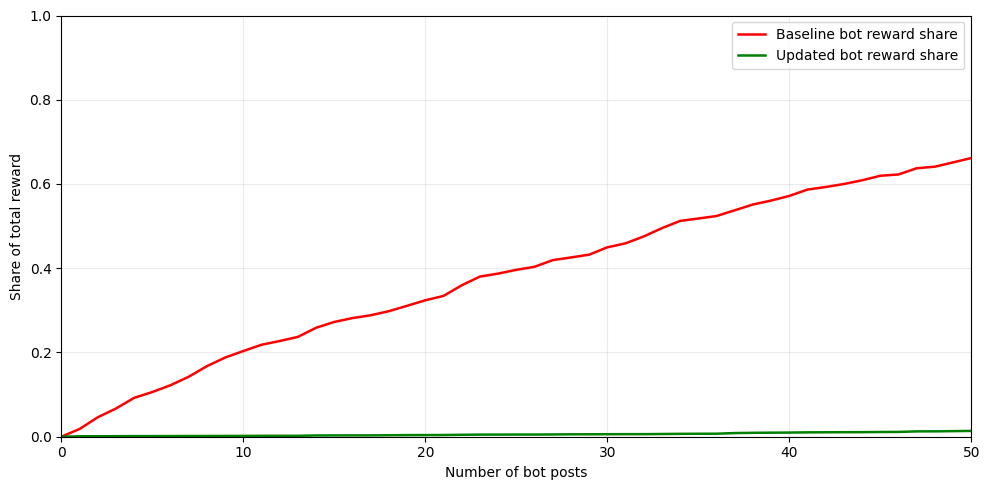

In [5]:
reward_share_columns = [
    "bot_posts",
    "scenario",
    "bot_reward",
    "human_reward",
    "total_reward",
    "bot_reward_share",
    "human_reward_share",
]
REWARD_SHARE_RESULTS = SWEEP_RESULTS[reward_share_columns]
display(REWARD_SHARE_RESULTS)
plot_reward_shares(SWEEP_RESULTS)
